# Generative AI – Assignment 2 · Question 2
## CycleGAN for Person Face ↔ Sketch translation (+ Flask demo)

**Dataset:** [Person Face Sketches](https://www.kaggle.com/datasets/almightyj/person-face-sketches)

Implementation follows *Zhu et al., "Unpaired Image-to-Image Translation using Cycle-Consistent Adversarial Networks" (ICCV 2017)*:
* two **ResNet generators** `G_AB` (photo → sketch) and `G_BA` (sketch → photo): 7×7 conv, 2 down-sampling convs, 9 residual blocks (6 for 128 px), 2 up-sampling convs, 7×7 conv, Tanh; reflection padding + instance norm
* two **70×70 PatchGAN discriminators** `D_A`, `D_B`
* **LSGAN** (least-squares) adversarial loss, **cycle-consistency loss** (λ = 10), **identity loss** (λ = 5)
* **image history buffer** of 50 images for the discriminators, Adam (lr 2e-4, β₁ = 0.5), learning rate linearly decayed to 0 in the second half of training
* checkpoint written **after every epoch** and training **resumes automatically** from the last checkpoint

### How to run this on Kaggle
1. **File → Import Notebook** → upload this `.ipynb`.
2. **Add Input → Datasets** → add *Person Face Sketches* (`almightyj/person-face-sketches`).
3. **Settings → Accelerator → GPU** (T4 ×1 or P100).
4. **Run All** (expect roughly 3–7 min per epoch with the defaults; progress is printed during every epoch). Outputs go to `/kaggle/working` (`checkpoints/`, `samples/`, `deploy/`, `deploy.zip`).
5. **If the session ends / you want to train longer:** *Save Version → Save & Run All (Commit)*. In the next session click *Add Input → Notebook Output* and add your previous run – the code finds `ckpt_last.pth` there automatically and continues from the last finished epoch.

Domain naming used everywhere below: **A = real face photos, B = sketches**.

In [19]:
# ------------------------------------------------------------------
# 0. Imports and configuration
# ------------------------------------------------------------------
import os, glob, random, time, json, shutil, itertools, sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.utils import make_grid, save_image

# ---------------- configuration (edit here) ----------------
SEED             = 42
IMG_SIZE         = 128          # 128 = fast; 256 is the paper's size (~4x slower, sharper images)
N_RES_BLOCKS     = 9 if IMG_SIZE >= 256 else 6
EPOCHS           = 30           # total epochs (paper: 200). Raise it if time allows.
DECAY_START      = 15           # learning rate is constant until this epoch, then decays linearly to 0
BATCH_SIZE       = 1            # paper uses 1 (instance norm); 2-4 is OK if you want more speed
LR               = 2e-4
BETA1            = 0.5
LAMBDA_CYC       = 10.0         # cycle-consistency weight
LAMBDA_ID        = 5.0          # identity-loss weight (0 disables it)
POOL_SIZE        = 50           # image history buffer size
MAX_TRAIN_SAMPLES = 2000        # random subset of each domain per epoch set (the full dataset has ~21k images -> hours per epoch). None = use everything
MAX_TEST_SAMPLES  = 300         # test images per domain used for evaluation
LOG_EVERY         = 250         # print training progress every N iterations
NUM_WORKERS      = 2
TIME_BUDGET_HOURS = None        # e.g. 11 -> stop cleanly (checkpoint saved) before Kaggle's session limit

DATA_ROOT  = '/kaggle/input'    # all attached datasets are scanned
PHOTO_DIR  = None               # optional manual override, e.g. '/kaggle/input/person-face-sketches/train/photos'
SKETCH_DIR = None               # optional manual override, e.g. '/kaggle/input/person-face-sketches/train/sketches'

WORK       = '/kaggle/working'
CKPT_DIR   = f'{WORK}/checkpoints'
SAMPLE_DIR = f'{WORK}/samples'
DEPLOY_DIR = f'{WORK}/deploy'
# ------------------------------------------------------------
for d in (CKPT_DIR, SAMPLE_DIR, DEPLOY_DIR, f'{DEPLOY_DIR}/templates'):
    os.makedirs(d, exist_ok=True)

def set_seed(seed):
    """Make runs reproducible."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print('Device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU only (very slow!)')

Device: cuda | Tesla T4


## 1. Model code
The networks and helper functions are written to `cyclegan_core.py` so that the **same file** is reused by the Flask app at the end (no duplicated code).

In [20]:
%%writefile /kaggle/working/cyclegan_core.py
"""cyclegan_core.py – CycleGAN networks and helpers shared by the training notebook and the Flask app."""
import random
import numpy as np
import torch
import torch.nn as nn
from PIL import Image


# ------------------------------------------------------------------ generator
class ResnetBlock(nn.Module):
    """Residual block: (reflect-pad, 3x3 conv, instance-norm, ReLU) x2 with a skip connection."""

    def __init__(self, dim):
        super().__init__()
        self.block = nn.Sequential(
            nn.ReflectionPad2d(1), nn.Conv2d(dim, dim, 3), nn.InstanceNorm2d(dim), nn.ReLU(True),
            nn.ReflectionPad2d(1), nn.Conv2d(dim, dim, 3), nn.InstanceNorm2d(dim),
        )

    def forward(self, x):
        return x + self.block(x)


class ResnetGenerator(nn.Module):
    """c7s1-64, d128, d256, R256 x n_blocks, u128, u64, c7s1-3 (Johnson et al. / CycleGAN paper)."""

    def __init__(self, ngf=64, n_blocks=9):
        super().__init__()
        layers = [nn.ReflectionPad2d(3), nn.Conv2d(3, ngf, 7), nn.InstanceNorm2d(ngf), nn.ReLU(True)]
        for i in range(2):                                   # down-sampling
            m = 2 ** i
            layers += [nn.Conv2d(ngf * m, ngf * m * 2, 3, 2, 1), nn.InstanceNorm2d(ngf * m * 2), nn.ReLU(True)]
        layers += [ResnetBlock(ngf * 4) for _ in range(n_blocks)]
        for i in range(2):                                   # up-sampling
            m = 2 ** (2 - i)
            layers += [nn.ConvTranspose2d(ngf * m, ngf * m // 2, 3, 2, 1, output_padding=1),
                       nn.InstanceNorm2d(ngf * m // 2), nn.ReLU(True)]
        layers += [nn.ReflectionPad2d(3), nn.Conv2d(ngf, 3, 7), nn.Tanh()]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


# ------------------------------------------------------------------ discriminator
class PatchDiscriminator(nn.Module):
    """70x70 PatchGAN: outputs a grid of real/fake scores, one per image patch."""

    def __init__(self, ndf=64, n_layers=3):
        super().__init__()
        layers = [nn.Conv2d(3, ndf, 4, 2, 1), nn.LeakyReLU(0.2, True)]
        nf = 1
        for n in range(1, n_layers):
            prev, nf = nf, min(2 ** n, 8)
            layers += [nn.Conv2d(ndf * prev, ndf * nf, 4, 2, 1), nn.InstanceNorm2d(ndf * nf), nn.LeakyReLU(0.2, True)]
        prev, nf = nf, min(2 ** n_layers, 8)
        layers += [nn.Conv2d(ndf * prev, ndf * nf, 4, 1, 1), nn.InstanceNorm2d(ndf * nf), nn.LeakyReLU(0.2, True),
                   nn.Conv2d(ndf * nf, 1, 4, 1, 1)]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


def init_weights(net, std=0.02):
    """Initialise conv weights from N(0, 0.02) as in the paper."""
    def _init(m):
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(m.weight, 0.0, std)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    net.apply(_init)
    return net


class ImagePool:
    """History buffer of previously generated images (stabilises discriminator training)."""

    def __init__(self, size=50):
        self.size, self.images = size, []

    def query(self, imgs):
        if self.size == 0:
            return imgs
        out = []
        for img in imgs:
            img = img.detach().unsqueeze(0)
            if len(self.images) < self.size:
                self.images.append(img); out.append(img)
            elif random.random() > 0.5:                      # return an old image, store the new one
                i = random.randint(0, self.size - 1)
                out.append(self.images[i].clone()); self.images[i] = img
            else:
                out.append(img)
        return torch.cat(out)


# ------------------------------------------------------------------ image helpers
def pil_to_tensor(img, size):
    """PIL image -> normalised tensor (1,3,size,size) in [-1, 1]."""
    img = img.convert('RGB').resize((size, size), Image.BICUBIC)
    a = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).permute(2, 0, 1)
    return (a * 2 - 1).unsqueeze(0)


def tensor_to_pil(t):
    """Tensor (1,3,H,W) or (3,H,W) in [-1, 1] -> PIL image."""
    t = t.detach().cpu()
    if t.dim() == 4:
        t = t[0]
    a = ((t.clamp(-1, 1) + 1) / 2 * 255).round().byte().permute(1, 2, 0).numpy()
    return Image.fromarray(a)


# ------------------------------------------------------------------ sketch-vs-photo detector features
def image_features(img):
    """Hand-crafted features (colour, brightness, edge statistics) used to tell sketches from photos."""
    im = img.convert('RGB').resize((128, 128))
    a = np.asarray(im, dtype=np.float32) / 255.0
    sat = np.asarray(im.convert('HSV'), dtype=np.float32)[..., 1] / 255.0
    gray = a.mean(axis=2)
    colourful = (np.abs(a[..., 0] - a[..., 1]) + np.abs(a[..., 1] - a[..., 2]) + np.abs(a[..., 0] - a[..., 2])).mean()
    gx = np.abs(np.diff(gray, axis=1)).mean()
    gy = np.abs(np.diff(gray, axis=0)).mean()
    hist = np.histogram(gray, bins=8, range=(0, 1))[0] / gray.size
    return np.array([sat.mean(), sat.std(), colourful, gray.mean(), gray.std(), (gray > 0.9).mean(), gx, gy, *hist],
                    dtype=np.float32)

Overwriting /kaggle/working/cyclegan_core.py


In [21]:
sys.path.insert(0, WORK)
from cyclegan_core import (ResnetGenerator, PatchDiscriminator, ImagePool, init_weights,
                           pil_to_tensor, tensor_to_pil, image_features)

def build_models():
    """Create G_AB (photo->sketch), G_BA (sketch->photo), D_A, D_B on the right device."""
    G_AB = init_weights(ResnetGenerator(n_blocks=N_RES_BLOCKS)).to(device)
    G_BA = init_weights(ResnetGenerator(n_blocks=N_RES_BLOCKS)).to(device)
    D_A  = init_weights(PatchDiscriminator()).to(device)
    D_B  = init_weights(PatchDiscriminator()).to(device)
    return G_AB, G_BA, D_A, D_B

_nets = build_models(); _G, _D = _nets[0], _nets[2]
print('Generator params: %.2fM | Discriminator params: %.2fM' %
      (sum(p.numel() for p in _G.parameters()) / 1e6, sum(p.numel() for p in _D.parameters()) / 1e6))
print('Discriminator output (patch grid) for a %dx%d input:' % (IMG_SIZE, IMG_SIZE),
      tuple(_D(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device)).shape[1:]))
del _G, _D, _nets

Generator params: 7.84M | Discriminator params: 2.76M
Discriminator output (patch grid) for a 128x128 input: (1, 14, 14)


## 2. Dataset
The full dataset has ~21,000 images per domain, which would take hours per epoch, so by default training uses a **random subset of 2,000 images per domain** (`MAX_TRAIN_SAMPLES`) at 128 px. The cell below scans the attached dataset, prints its folder layout, and separates **photos (domain A)** from **sketches (domain B)** by folder name (any path containing "sketch" is a sketch). If your copy of the dataset is organised differently, set `PHOTO_DIR` / `SKETCH_DIR` in the configuration cell.
Training is *unpaired* – for every photo a random sketch is drawn – exactly as CycleGAN requires. If the dataset has a `test` folder it is used as the test set, otherwise 10 % of the images are held out.

In [22]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp')

def list_images(root):
    """Recursively list image files below `root`."""
    return sorted(os.path.join(dp, f) for dp, _, fn in os.walk(root) for f in fn if f.lower().endswith(IMG_EXT))

def rel_path(p):
    """Lower-cased path relative to the dataset folder (so the dataset's own name does not interfere)."""
    low = p.replace('\\', '/').lower()
    return low.split('person-face-sketches')[-1] if 'person-face-sketches' in low else low

# --- show the dataset layout (first 3 levels) so you can verify it is read correctly
def show_tree(root, max_depth=3):
    for dp, dirs, fn in os.walk(root):
        depth = dp[len(root):].count(os.sep)
        if depth <= max_depth:
            n_img = sum(f.lower().endswith(IMG_EXT) for f in fn)
            print('  ' * depth + os.path.basename(dp) + f'/   ({n_img} images)')
        if depth >= max_depth:
            dirs[:] = []
show_tree(DATA_ROOT)

# --- separate the two domains
if PHOTO_DIR and SKETCH_DIR:
    photos, sketches = list_images(PHOTO_DIR), list_images(SKETCH_DIR)
else:
    all_imgs = list_images(DATA_ROOT)
    sketches = [p for p in all_imgs if 'sketch' in rel_path(p)]
    photos   = [p for p in all_imgs if 'sketch' not in rel_path(p)]
print(f'\nPhotos (domain A): {len(photos)}   Sketches (domain B): {len(sketches)}')
assert photos and sketches, ('Could not separate photos from sketches - check the tree above and set '
                             'PHOTO_DIR / SKETCH_DIR in the configuration cell.')
print('example photo   :', photos[0]); print('example sketch  :', sketches[0])

# --- train / test split
def of_part(files, part):
    return [f for f in files if f'/{part}/' in rel_path(f)]

test_photos, test_sketches = of_part(photos, 'test'), of_part(sketches, 'test')
if test_photos and test_sketches:
    tp, ts = set(test_photos), set(test_sketches)
    train_photos   = [f for f in photos if f not in tp]
    train_sketches = [f for f in sketches if f not in ts]
else:                                                    # no official test folder -> hold out 10 %
    rng = random.Random(SEED)
    rng.shuffle(photos); rng.shuffle(sketches)
    k_p, k_s = max(1, len(photos) // 10), max(1, len(sketches) // 10)
    test_photos, train_photos = photos[:k_p], photos[k_p:]
    test_sketches, train_sketches = sketches[:k_s], sketches[k_s:]

# random (seeded) subsets - taking the first N files would give only a few different people
rs = random.Random(SEED)
if MAX_TRAIN_SAMPLES:
    train_photos   = rs.sample(train_photos, min(MAX_TRAIN_SAMPLES, len(train_photos)))
    train_sketches = rs.sample(train_sketches, min(MAX_TRAIN_SAMPLES, len(train_sketches)))
if MAX_TEST_SAMPLES:
    test_photos   = rs.sample(test_photos, min(MAX_TEST_SAMPLES, len(test_photos)))
    test_sketches = rs.sample(test_sketches, min(MAX_TEST_SAMPLES, len(test_sketches)))
print(f'train: {len(train_photos)} photos / {len(train_sketches)} sketches | '
      f'test: {len(test_photos)} photos / {len(test_sketches)} sketches')

input/   (0 images)
  datasets/   (0 images)
    almightyj/   (0 images)
      person-face-sketches/   (0 images)

Photos (domain A): 22334   Sketches (domain B): 22334
example photo   : /kaggle/input/datasets/almightyj/person-face-sketches/test/photos/10132.jpg
example sketch  : /kaggle/input/datasets/almightyj/person-face-sketches/test/sketches/10132.jpg
train: 2000 photos / 2000 sketches | test: 300 photos / 300 sketches


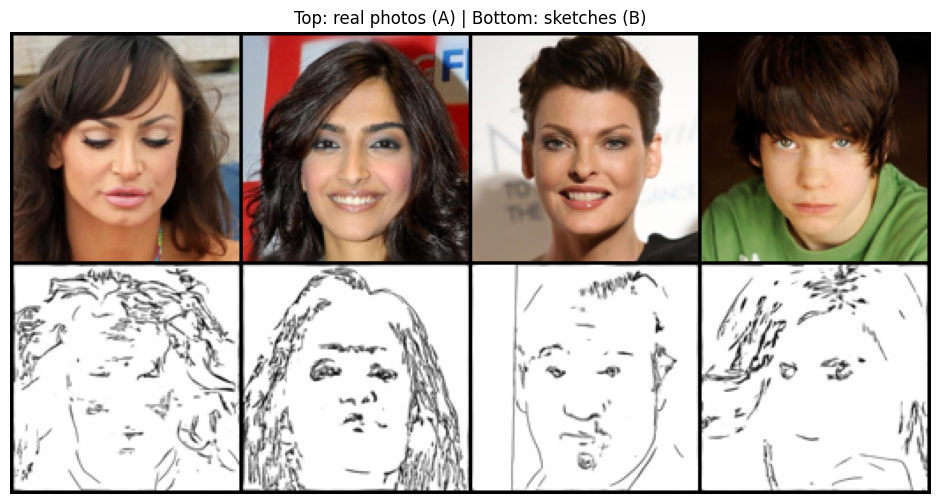

In [37]:
class UnpairedDataset(Dataset):
    """Returns (photo, sketch) tensors in [-1,1]. Domains are sampled independently (unpaired)."""

    def __init__(self, files_A, files_B, size, train=True):
        self.A, self.B, self.train = files_A, files_B, train
        load = int(size * 1.117)                        # 286 for 256: resize then random-crop (jitter)
        if train:
            self.tf = T.Compose([T.Resize((load, load), T.InterpolationMode.BICUBIC), T.RandomCrop(size),
                                 T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize((.5,) * 3, (.5,) * 3)])
        else:
            self.tf = T.Compose([T.Resize((size, size), T.InterpolationMode.BICUBIC), T.ToTensor(),
                                 T.Normalize((.5,) * 3, (.5,) * 3)])

    def __len__(self):
        return max(len(self.A), len(self.B))

    def __getitem__(self, i):
        a = self.A[i % len(self.A)]
        b = random.choice(self.B) if self.train else self.B[i % len(self.B)]
        return (self.tf(Image.open(a).convert('RGB')), self.tf(Image.open(b).convert('RGB')))

train_ds = UnpairedDataset(train_photos, train_sketches, IMG_SIZE, train=True)
test_ds  = UnpairedDataset(test_photos, test_sketches, IMG_SIZE, train=False)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          drop_last=True, pin_memory=(device.type == 'cuda'))
test_loader  = DataLoader(test_ds, batch_size=4, shuffle=False, num_workers=0)

a, b = next(iter(test_loader))
grid = make_grid(torch.cat([a, b]) * 0.5 + 0.5, nrow=4)
plt.figure(figsize=(12, 6)); plt.imshow(grid.permute(1, 2, 0)); plt.axis('off')
plt.title('Top: real photos (A) | Bottom: sketches (B)'); plt.show()

## 3. Training
**Generator objective**
`L_G = L_GAN(G_AB, D_B) + L_GAN(G_BA, D_A) + λ_cyc · (‖G_BA(G_AB(a)) − a‖₁ + ‖G_AB(G_BA(b)) − b‖₁) + λ_id · (‖G_BA(a) − a‖₁ + ‖G_AB(b) − b‖₁)`

**Discriminator objective** (LSGAN): `L_D = ½[(D(real) − 1)² + D(fake)²]` for each domain, where fakes come from the image history buffer.

* A full checkpoint (`ckpt_last.pth`: all 4 networks, both optimisers, both LR schedulers, epoch counter, loss history) is written **atomically after every epoch**.
* A sample grid (`samples/epoch_XXX.png`: real A → fake B → reconstructed A, real B → fake A → reconstructed B) is written after every epoch.
* Re-running the cell **resumes** from the last checkpoint – in this session's `/kaggle/working/checkpoints` or from a previous run added as an input.

In [45]:
def find_resume_checkpoint():
    """Look for the newest ckpt_last.pth in this session or in any attached notebook output."""
    cands = [f'{CKPT_DIR}/ckpt_last.pth'] + glob.glob('/kaggle/input/**/ckpt_last.pth', recursive=True)
    cands = [c for c in cands if os.path.isfile(c)]
    return max(cands, key=os.path.getmtime) if cands else None

def save_checkpoint(path, epoch, nets, opts, scheds, history):
    """Atomically save everything needed to resume training (write to tmp file, then rename)."""
    G_AB, G_BA, D_A, D_B = nets
    state = dict(epoch=epoch, img_size=IMG_SIZE, n_res_blocks=N_RES_BLOCKS,
                 G_AB=G_AB.state_dict(), G_BA=G_BA.state_dict(), D_A=D_A.state_dict(), D_B=D_B.state_dict(),
                 opt_G=opts[0].state_dict(), opt_D=opts[1].state_dict(),
                 sched_G=scheds[0].state_dict(), sched_D=scheds[1].state_dict(), history=history)
    torch.save(state, path + '.tmp')
    os.replace(path + '.tmp', path)

@torch.no_grad()
def save_samples(G_AB, G_BA, real_A, real_B, path):
    """Save a grid: [A | G_AB(A) | G_BA(G_AB(A))] and [B | G_BA(B) | G_AB(G_BA(B))]."""
    fake_B, fake_A = G_AB(real_A), G_BA(real_B)
    rec_A, rec_B = G_BA(fake_B), G_AB(fake_A)
    grid = torch.cat([real_A, fake_B, rec_A, real_B, fake_A, rec_B])
    save_image(grid * 0.5 + 0.5, path, nrow=real_A.size(0), padding=2)

def train():
    """Full CycleGAN training loop with per-epoch checkpointing and automatic resume."""
    set_seed(SEED)
    G_AB, G_BA, D_A, D_B = nets = build_models()
    opt_G = torch.optim.Adam(itertools.chain(G_AB.parameters(), G_BA.parameters()), lr=LR, betas=(BETA1, 0.999))
    opt_D = torch.optim.Adam(itertools.chain(D_A.parameters(), D_B.parameters()), lr=LR, betas=(BETA1, 0.999))
    # constant LR, then linear decay to zero
    lr_rule = lambda e: 1.0 if e < DECAY_START else max(0.0, 1.0 - (e - DECAY_START) / float(max(1, EPOCHS - DECAY_START)))
    sched_G = torch.optim.lr_scheduler.LambdaLR(opt_G, lr_rule)
    sched_D = torch.optim.lr_scheduler.LambdaLR(opt_D, lr_rule)
    history, start_epoch = [], 0

    ckpt_path = find_resume_checkpoint()
    if ckpt_path:
        st = torch.load(ckpt_path, map_location=device)
        for net, key in zip(nets, ('G_AB', 'G_BA', 'D_A', 'D_B')):
            net.load_state_dict(st[key])
        opt_G.load_state_dict(st['opt_G']); opt_D.load_state_dict(st['opt_D'])
        sched_G.load_state_dict(st['sched_G']); sched_D.load_state_dict(st['sched_D'])
        history, start_epoch = st['history'], st['epoch']
        print(f'>>> Resuming from {ckpt_path} (finished epochs: {start_epoch})')
    else:
        print('>>> No checkpoint found - starting from scratch')

    gan_loss, l1 = nn.MSELoss(), nn.L1Loss()                    # LSGAN + L1
    pool_A, pool_B = ImagePool(POOL_SIZE), ImagePool(POOL_SIZE)
    fixed_A, fixed_B = next(iter(test_loader))
    fixed_A, fixed_B = fixed_A.to(device), fixed_B.to(device)
    t_start = time.time()

    for epoch in range(start_epoch, EPOCHS):
        t_ep, sums, n_it = time.time(), {}, 0
        for real_A, real_B in train_loader:
            real_A, real_B = real_A.to(device, non_blocking=True), real_B.to(device, non_blocking=True)

            # ---------------- generators ----------------
            opt_G.zero_grad(set_to_none=True)
            fake_B, fake_A = G_AB(real_A), G_BA(real_B)
            rec_A, rec_B = G_BA(fake_B), G_AB(fake_A)
            pred_fB, pred_fA = D_B(fake_B), D_A(fake_A)
            loss_gan = gan_loss(pred_fB, torch.ones_like(pred_fB)) + gan_loss(pred_fA, torch.ones_like(pred_fA))
            loss_cyc = (l1(rec_A, real_A) + l1(rec_B, real_B)) * LAMBDA_CYC
            loss_id = torch.zeros((), device=device)
            if LAMBDA_ID > 0:
                loss_id = (l1(G_BA(real_A), real_A) + l1(G_AB(real_B), real_B)) * LAMBDA_ID
            loss_G = loss_gan + loss_cyc + loss_id
            loss_G.backward(); opt_G.step()

            # ---------------- discriminators ----------------
            opt_D.zero_grad(set_to_none=True)
            pr, pf = D_A(real_A), D_A(pool_A.query(fake_A))
            loss_DA = 0.5 * (gan_loss(pr, torch.ones_like(pr)) + gan_loss(pf, torch.zeros_like(pf)))
            pr, pf = D_B(real_B), D_B(pool_B.query(fake_B))
            loss_DB = 0.5 * (gan_loss(pr, torch.ones_like(pr)) + gan_loss(pf, torch.zeros_like(pf)))
            (loss_DA + loss_DB).backward(); opt_D.step()

            for k, v in dict(G=loss_G, gan=loss_gan, cycle=loss_cyc, identity=loss_id, D_A=loss_DA, D_B=loss_DB).items():
                sums[k] = sums.get(k, 0.0) + v.item()
            n_it += 1
            if n_it % LOG_EVERY == 0:
                print(f'   epoch {epoch + 1} | iter {n_it}/{len(train_loader)} | {time.time() - t_ep:.0f}s elapsed', flush=True)

        sched_G.step(); sched_D.step()
        rec = {k: v / max(1, n_it) for k, v in sums.items()}; rec['epoch'] = epoch + 1
        rec['lr'] = opt_G.param_groups[0]['lr']; history.append(rec)

        # ---- save everything after EVERY epoch
        save_checkpoint(f'{CKPT_DIR}/ckpt_last.pth', epoch + 1, nets, (opt_G, opt_D), (sched_G, sched_D), history)
        save_samples(G_AB, G_BA, fixed_A, fixed_B, f'{SAMPLE_DIR}/epoch_{epoch + 1:03d}.png')
        if (epoch + 1) % 10 == 0:                                    # keep a generator snapshot every 10 epochs
            torch.save(dict(G_AB=G_AB.state_dict(), G_BA=G_BA.state_dict(), img_size=IMG_SIZE,
                            n_res_blocks=N_RES_BLOCKS), f'{CKPT_DIR}/generators_epoch_{epoch + 1:03d}.pth')

        print(f"epoch {epoch + 1:3d}/{EPOCHS} | {time.time() - t_ep:6.1f}s | G {rec['G']:.3f} (gan {rec['gan']:.3f} "
              f"cyc {rec['cycle']:.3f} id {rec['identity']:.3f}) | D_A {rec['D_A']:.3f} D_B {rec['D_B']:.3f} | lr {rec['lr']:.2e}")

        if TIME_BUDGET_HOURS and (time.time() - t_start) / 3600 > TIME_BUDGET_HOURS:
            print(f'Time budget of {TIME_BUDGET_HOURS} h reached - stopping. Re-run the cell (or a new session) to resume.')
            break
    return nets, history

In [9]:
nets, history = train()

>>> Resuming from /kaggle/working/checkpoints/ckpt_last.pth (finished epochs: 20)
   epoch 21 | iter 250/2000 | 35s elapsed
   epoch 21 | iter 500/2000 | 69s elapsed
   epoch 21 | iter 750/2000 | 103s elapsed
   epoch 21 | iter 1000/2000 | 137s elapsed
   epoch 21 | iter 1250/2000 | 171s elapsed
   epoch 21 | iter 1500/2000 | 206s elapsed
   epoch 21 | iter 1750/2000 | 240s elapsed
   epoch 21 | iter 2000/2000 | 274s elapsed
epoch  21/30 |  274.7s | G 3.372 (gan 1.381 cyc 1.442 id 0.548) | D_A 0.157 D_B 0.012 | lr 1.20e-04
   epoch 22 | iter 250/2000 | 34s elapsed
   epoch 22 | iter 500/2000 | 68s elapsed
   epoch 22 | iter 750/2000 | 103s elapsed
   epoch 22 | iter 1000/2000 | 137s elapsed
   epoch 22 | iter 1250/2000 | 171s elapsed
   epoch 22 | iter 1500/2000 | 205s elapsed
   epoch 22 | iter 1750/2000 | 240s elapsed
   epoch 22 | iter 2000/2000 | 274s elapsed
epoch  22/30 |  274.3s | G 3.322 (gan 1.393 cyc 1.394 id 0.535) | D_A 0.157 D_B 0.006 | lr 1.07e-04
   epoch 23 | iter 250/2

## 4. Training curves and sample evolution

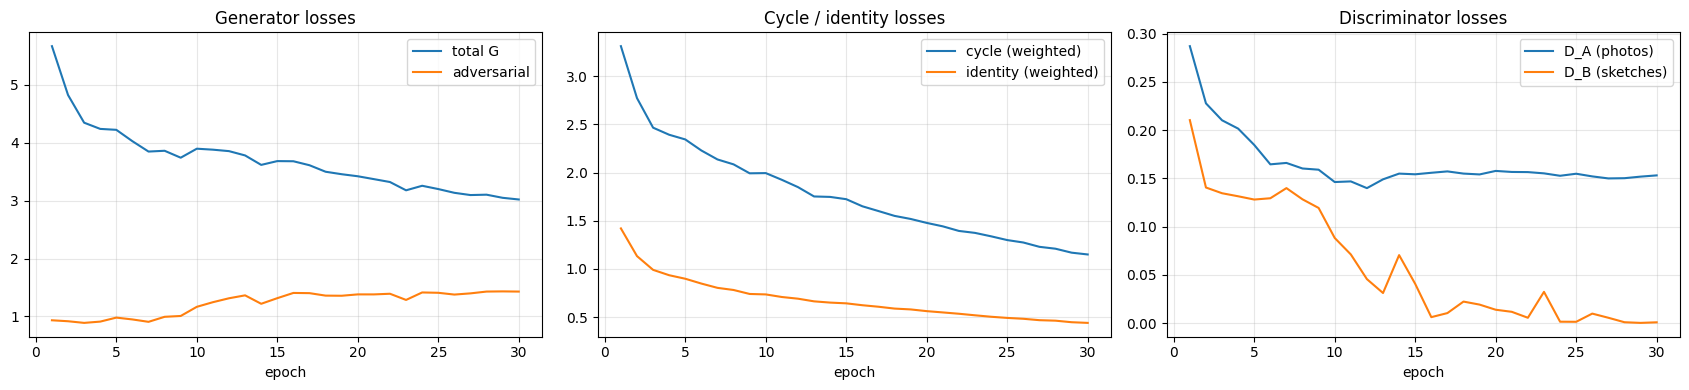

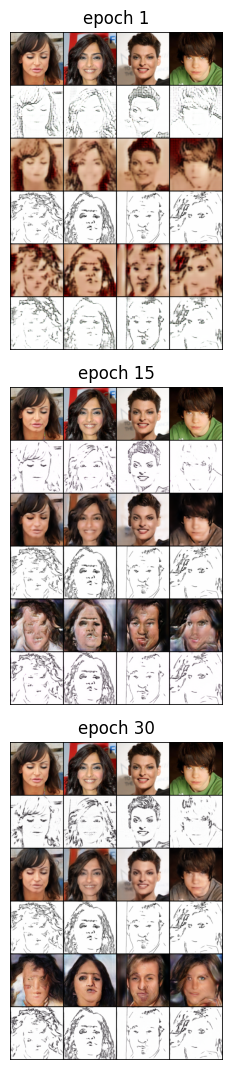

In [10]:
ep = [h['epoch'] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(ep, [h['G'] for h in history], label='total G'); axes[0].plot(ep, [h['gan'] for h in history], label='adversarial')
axes[0].set_title('Generator losses'); axes[0].legend()
axes[1].plot(ep, [h['cycle'] for h in history], label='cycle (weighted)'); axes[1].plot(ep, [h['identity'] for h in history], label='identity (weighted)')
axes[1].set_title('Cycle / identity losses'); axes[1].legend()
axes[2].plot(ep, [h['D_A'] for h in history], label='D_A (photos)'); axes[2].plot(ep, [h['D_B'] for h in history], label='D_B (sketches)')
axes[2].set_title('Discriminator losses'); axes[2].legend()
for a in axes: a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{WORK}/cyclegan_loss_curves.png', dpi=130); plt.show()

# samples from the first, a middle and the last epoch (rows: A, G_AB(A), rec A, B, G_BA(B), rec B)
last = len(history)
picks = sorted({1, max(1, last // 2), last})
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 3.6 * len(picks)))
for ax, e in zip(np.atleast_1d(axes), picks):
    ax.imshow(plt.imread(f'{SAMPLE_DIR}/epoch_{e:03d}.png')); ax.axis('off'); ax.set_title(f'epoch {e}')
plt.tight_layout(); plt.show()

## 5. Testing: face → sketch and sketch → face
The generators are reloaded from the last checkpoint (this also proves that resuming / loading works). Because the task is unpaired, we measure **cycle-reconstruction quality** (PSNR / SSIM of `G_BA(G_AB(a))` vs. `a`, and `G_AB(G_BA(b))` vs. `b`) and inspect the translations visually.

Loaded checkpoint of epoch 30
photo->sketch->photo     PSNR = 25.33 dB   SSIM = 0.879
sketch->photo->sketch    PSNR = 25.60 dB   SSIM = 0.935


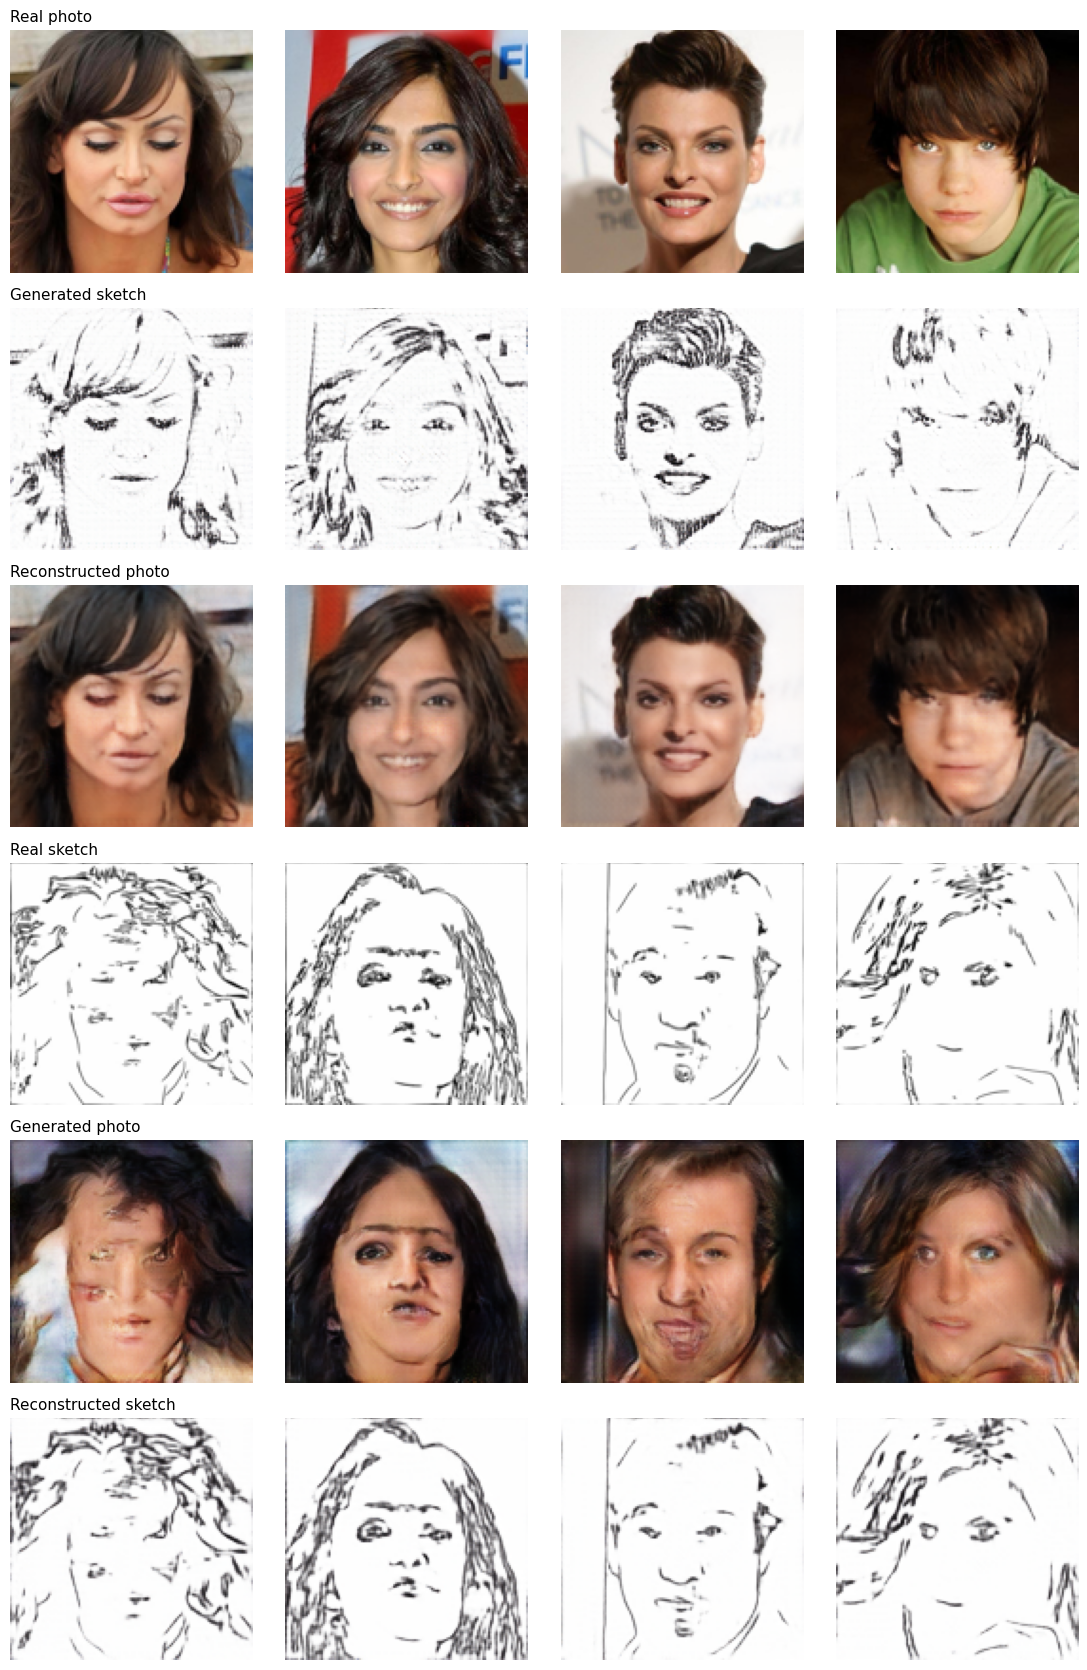

In [11]:
from skimage.metrics import structural_similarity as ssim_fn

def load_generators(path=None):
    """Load G_AB and G_BA (eval mode) from a checkpoint."""
    path = path or f'{CKPT_DIR}/ckpt_last.pth'
    st = torch.load(path, map_location=device)
    G_AB = ResnetGenerator(n_blocks=st['n_res_blocks']).to(device); G_BA = ResnetGenerator(n_blocks=st['n_res_blocks']).to(device)
    G_AB.load_state_dict(st['G_AB']); G_BA.load_state_dict(st['G_BA'])
    return G_AB.eval(), G_BA.eval(), st

G_AB, G_BA, st = load_generators()
print('Loaded checkpoint of epoch', st['epoch'])

@torch.no_grad()
def cycle_metrics(loader):
    """Mean PSNR / SSIM of cycle reconstructions over the whole test set, for both directions."""
    res = {'photo->sketch->photo': [[], []], 'sketch->photo->sketch': [[], []]}
    for a, b in loader:
        a, b = a.to(device), b.to(device)
        for name, x, y in (('photo->sketch->photo', a, G_BA(G_AB(a))), ('sketch->photo->sketch', b, G_AB(G_BA(b)))):
            x = (x * .5 + .5).clamp(0, 1).cpu().numpy(); y = (y * .5 + .5).clamp(0, 1).cpu().numpy()
            for i in range(len(x)):
                mse = max(((x[i] - y[i]) ** 2).mean(), 1e-10)
                res[name][0].append(10 * np.log10(1 / mse))
                res[name][1].append(ssim_fn(x[i], y[i], data_range=1.0, channel_axis=0))
    return {k: dict(PSNR=float(np.mean(v[0])), SSIM=float(np.mean(v[1]))) for k, v in res.items()}

metrics = cycle_metrics(test_loader)
for k, v in metrics.items():
    print(f"{k:24s} PSNR = {v['PSNR']:.2f} dB   SSIM = {v['SSIM']:.3f}")
json.dump(metrics, open(f'{WORK}/cycle_metrics.json', 'w'), indent=2)

@torch.no_grad()
def show_translations(n=4):
    """Plot test photos -> sketches (-> reconstruction) and test sketches -> photos (-> reconstruction)."""
    a, b = next(iter(test_loader)); a, b = a[:n].to(device), b[:n].to(device)
    fb, fa = G_AB(a), G_BA(b); ra, rb = G_BA(fb), G_AB(fa)
    rows = [('Real photo', a), ('Generated sketch', fb), ('Reconstructed photo', ra),
            ('Real sketch', b), ('Generated photo', fa), ('Reconstructed sketch', rb)]
    fig, axes = plt.subplots(len(rows), n, figsize=(2.8 * n, 2.8 * len(rows)))
    for r, (title, t) in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(tensor_to_pil(t[c])); axes[r, c].axis('off')
        axes[r, 0].set_title(title, loc='left', fontsize=11)
    plt.tight_layout(); plt.savefig(f'{WORK}/cyclegan_test_results.png', dpi=120); plt.show()

show_translations(4)

## 6. Sketch-vs-photo detector (for the UI's "automatic detection")
The UI must decide whether an uploaded picture is a sketch or a real face. A small logistic-regression classifier on simple colour / brightness / edge statistics (`image_features`) is trained on the training images; it is tiny, fast, and typically >99 % accurate on this dataset.

In [12]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def feats(files, limit=600):
    """Feature matrix for (at most `limit`) image files."""
    return np.stack([image_features(Image.open(f)) for f in files[:limit]])

Xtr = np.concatenate([feats(train_photos), feats(train_sketches)])
ytr = np.concatenate([np.zeros(min(600, len(train_photos))), np.ones(min(600, len(train_sketches)))])   # 0 = photo, 1 = sketch
Xte = np.concatenate([feats(test_photos, 300), feats(test_sketches, 300)])
yte = np.concatenate([np.zeros(min(300, len(test_photos))), np.ones(min(300, len(test_sketches)))])

detector = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=2.0)).fit(Xtr, ytr)
print(f'Detector accuracy - train: {detector.score(Xtr, ytr):.3f} | test: {detector.score(Xte, yte):.3f}')
joblib.dump(detector, f'{WORK}/detector.joblib')

Detector accuracy - train: 1.000 | test: 1.000


['/kaggle/working/detector.joblib']

## 7. Flask user interface
The next three cells write the app files into `/kaggle/working/deploy/`. The app
* accepts an **uploaded image** or a **live webcam capture**,
* **automatically detects** whether it is a sketch or a real face (with a manual override),
* converts it (sketch → face, face → sketch) and returns the result in the browser.

Afterwards the bundle (`deploy.zip`) contains everything – `app.py`, the template, `cyclegan_core.py`, the generator weights and the detector – so you can download it and run it on your own machine with `pip install -r requirements.txt && python app.py` (webcam access needs `localhost` or HTTPS).

In [13]:
%%writefile /kaggle/working/deploy/app.py
"""Flask demo for the CycleGAN face <-> sketch model.

Run:  pip install -r requirements.txt && python app.py   ->  http://localhost:5000
"""
import base64, io, os

import joblib
import numpy as np
import torch
from flask import Flask, jsonify, render_template, request
from PIL import Image

from cyclegan_core import ResnetGenerator, image_features, pil_to_tensor, tensor_to_pil

BASE = os.path.dirname(os.path.abspath(__file__))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---------------------------------------------------------------- load models once at start-up
ckpt = torch.load(os.path.join(BASE, 'generators.pth'), map_location=device)
IMG_SIZE = ckpt['img_size']
G_AB = ResnetGenerator(n_blocks=ckpt['n_res_blocks']).to(device)   # photo  -> sketch
G_BA = ResnetGenerator(n_blocks=ckpt['n_res_blocks']).to(device)   # sketch -> photo
G_AB.load_state_dict(ckpt['G_AB']); G_BA.load_state_dict(ckpt['G_BA'])
G_AB.eval(); G_BA.eval()

det_path = os.path.join(BASE, 'detector.joblib')
detector = joblib.load(det_path) if os.path.exists(det_path) else None

app = Flask(__name__)
app.config['MAX_CONTENT_LENGTH'] = 16 * 1024 * 1024   # 16 MB upload limit


def detect_domain(img):
    """Return ('sketch' | 'photo', confidence). Uses the trained detector, or a simple saturation rule as fallback."""
    f = image_features(img)
    if detector is not None:
        p_sketch = float(detector.predict_proba(f[None])[0, 1])
    else:
        p_sketch = 1.0 if f[0] < 0.08 else 0.0          # sketches are (almost) colourless
    return ('sketch', p_sketch) if p_sketch >= 0.5 else ('photo', 1 - p_sketch)


def to_data_url(pil_img):
    """PIL image -> base64 PNG data URL for the browser."""
    buf = io.BytesIO(); pil_img.save(buf, format='PNG')
    return 'data:image/png;base64,' + base64.b64encode(buf.getvalue()).decode()


@app.route('/')
def index():
    return render_template('index.html')


@app.route('/convert', methods=['POST'])
def convert():
    """Accepts multipart form data: image (file) and optional mode = auto | photo | sketch."""
    if 'image' not in request.files:
        return jsonify(error='No image received.'), 400
    try:
        img = Image.open(request.files['image'].stream).convert('RGB')
    except Exception:
        return jsonify(error='Could not read the file as an image.'), 400

    mode = request.form.get('mode', 'auto')
    if mode in ('photo', 'sketch'):
        domain, conf = mode, 1.0                         # manual override
    else:
        domain, conf = detect_domain(img)

    x = pil_to_tensor(img, IMG_SIZE).to(device)
    with torch.no_grad():
        y = G_BA(x) if domain == 'sketch' else G_AB(x)   # sketch -> face  |  face -> sketch
    return jsonify(detected=domain, confidence=round(conf, 3),
                   direction='sketch -> face' if domain == 'sketch' else 'face -> sketch',
                   input=to_data_url(img.resize((IMG_SIZE, IMG_SIZE))), output=to_data_url(tensor_to_pil(y)))


if __name__ == '__main__':
    app.run(host='0.0.0.0', port=int(os.environ.get('PORT', 5000)), debug=False)

Writing /kaggle/working/deploy/app.py


In [15]:
%%writefile /kaggle/working/deploy/templates/index.html
<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Face &harr; Sketch (CycleGAN)</title>
<style>
  :root { --bg:#f5f6fa; --card:#fff; --ink:#1f2430; --muted:#6b7280; --accent:#4f46e5; --line:#e5e7eb; }
  @media (prefers-color-scheme: dark) { :root { --bg:#12141a; --card:#1b1e27; --ink:#e8eaf0; --muted:#9aa1b2; --line:#2b3040; } }
  * { box-sizing: border-box; }
  body { margin:0; font-family: system-ui, -apple-system, Segoe UI, Roboto, sans-serif; background:var(--bg); color:var(--ink); }
  main { max-width: 980px; margin: 0 auto; padding: 28px 18px 60px; }
  h1 { margin: 0 0 4px; font-size: 1.6rem; } p.sub { margin: 0 0 22px; color: var(--muted); }
  .card { background: var(--card); border: 1px solid var(--line); border-radius: 14px; padding: 18px; margin-bottom: 18px; }
  .row { display:flex; flex-wrap:wrap; gap:10px; align-items:center; }
  button, select { font: inherit; padding: 9px 14px; border-radius: 9px; border: 1px solid var(--line); background: var(--card); color: var(--ink); cursor: pointer; }
  button.primary { background: var(--accent); border-color: var(--accent); color:#fff; font-weight:600; }
  button:disabled { opacity:.5; cursor:not-allowed; }
  input[type=file] { display:none; }
  .grid { display:grid; grid-template-columns: 1fr 1fr; gap:16px; }
  @media (max-width: 680px) { .grid { grid-template-columns: 1fr; } }
  .box { border:1px dashed var(--line); border-radius:12px; min-height:260px; display:flex; align-items:center; justify-content:center; flex-direction:column; overflow:hidden; }
  .box img, .box video { width:100%; display:block; }
  .box span.ph { color: var(--muted); padding: 20px; text-align:center; }
  h3 { margin: 0 0 10px; font-size: 1rem; }
  .badge { display:inline-block; padding:3px 10px; border-radius:99px; background: var(--accent); color:#fff; font-size:.85rem; margin-left:8px; }
  #status { color: var(--muted); margin-top: 10px; min-height: 1.3em; }
  #status.err { color:#dc2626; }
</style>
</head>
<body>
<main>
  <h1>Face &harr; Sketch translator</h1>
  <p class="sub">Upload a picture or use your camera. The app detects whether it is a sketch or a real face and converts it with a CycleGAN.</p>

  <div class="card">
    <div class="row">
      <label for="file"><button type="button" onclick="document.getElementById('file').click()">&#128193; Upload image</button></label>
      <input id="file" type="file" accept="image/*">
      <button type="button" id="camBtn">&#128247; Use camera</button>
      <button type="button" id="snapBtn" style="display:none">&#9679; Capture</button>
      <label>Mode:
        <select id="mode">
          <option value="auto">Auto-detect</option>
          <option value="photo">It is a face photo</option>
          <option value="sketch">It is a sketch</option>
        </select>
      </label>
      <button type="button" class="primary" id="goBtn" disabled>Convert</button>
    </div>
    <div id="status">Choose an image to begin.</div>
  </div>

  <div class="grid">
    <div class="card"><h3>Input <span id="detected" class="badge" style="display:none"></span></h3>
      <div class="box" id="inBox"><span class="ph">No image yet</span></div></div>
    <div class="card"><h3>Result <span id="dir" class="badge" style="display:none"></span></h3>
      <div class="box" id="outBox"><span class="ph">The converted image will appear here</span></div></div>
  </div>
  <canvas id="cv" style="display:none"></canvas>
</main>

<script>
const $ = id => document.getElementById(id);
let blob = null, stream = null;

function setStatus(msg, err=false) { $('status').textContent = msg; $('status').className = err ? 'err' : ''; }
function showInput(url) { $('inBox').innerHTML = '<img src="' + url + '" alt="input">'; }

$('file').addEventListener('change', e => {
  const f = e.target.files[0]; if (!f) return;
  stopCamera(); blob = f; showInput(URL.createObjectURL(f));
  $('goBtn').disabled = false; setStatus('Image ready - press Convert.');
});

async function startCamera() {
  try {
    stream = await navigator.mediaDevices.getUserMedia({ video: { facingMode: 'user' }, audio: false });
    const v = document.createElement('video'); v.autoplay = true; v.playsInline = true; v.srcObject = stream; v.id = 'vid';
    $('inBox').innerHTML = ''; $('inBox').appendChild(v);
    $('snapBtn').style.display = ''; $('camBtn').textContent = 'Stop camera'; setStatus('Camera on - press Capture.');
  } catch (err) { setStatus('Camera not available: ' + err.message + ' (camera needs https or localhost).', true); }
}
function stopCamera() {
  if (stream) { stream.getTracks().forEach(t => t.stop()); stream = null; }
  $('snapBtn').style.display = 'none'; $('camBtn').innerHTML = '&#128247; Use camera';
}
$('camBtn').onclick = () => stream ? stopCamera() : startCamera();

$('snapBtn').onclick = () => {
  const v = $('vid'), c = $('cv'); c.width = v.videoWidth; c.height = v.videoHeight;
  c.getContext('2d').drawImage(v, 0, 0);
  c.toBlob(b => { blob = b; stopCamera(); showInput(URL.createObjectURL(b)); $('goBtn').disabled = false; setStatus('Photo captured - press Convert.'); }, 'image/jpeg', 0.92);
};

$('goBtn').onclick = async () => {
  if (!blob) return;
  $('goBtn').disabled = true; setStatus('Converting...');
  const fd = new FormData(); fd.append('image', blob, 'input.jpg'); fd.append('mode', $('mode').value);
  try {
    const r = await fetch('/convert', { method: 'POST', body: fd });
    const j = await r.json(); if (!r.ok) throw new Error(j.error || 'Server error');
    showInput(j.input);
    $('outBox').innerHTML = '<img src="' + j.output + '" alt="output">';
    $('detected').style.display = ''; $('detected').textContent = 'detected: ' + j.detected + ' (' + Math.round(j.confidence * 100) + '%)';
    $('dir').style.display = ''; $('dir').textContent = j.direction;
    setStatus('Done.');
  } catch (e) { setStatus(e.message, true); }
  $('goBtn').disabled = false;
};
</script>
</body>
</html>

Overwriting /kaggle/working/deploy/templates/index.html


In [16]:
# Bundle everything the demo needs: generator weights, detector, shared model code, requirements
torch.save(dict(G_AB=G_AB.state_dict(), G_BA=G_BA.state_dict(), img_size=IMG_SIZE, n_res_blocks=N_RES_BLOCKS,
                epoch=st['epoch']), f'{DEPLOY_DIR}/generators.pth')
shutil.copy(f'{WORK}/cyclegan_core.py', f'{DEPLOY_DIR}/cyclegan_core.py')
shutil.copy(f'{WORK}/detector.joblib', f'{DEPLOY_DIR}/detector.joblib')
open(f'{DEPLOY_DIR}/requirements.txt', 'w').write('flask\ntorch\ntorchvision\npillow\nnumpy\nscikit-learn\njoblib\n')
shutil.make_archive(f'{WORK}/deploy', 'zip', DEPLOY_DIR)
print(sorted(os.listdir(DEPLOY_DIR)), '->', f'{WORK}/deploy.zip', f'({os.path.getsize(WORK + "/deploy.zip") / 1e6:.0f} MB)')

['app.py', 'cyclegan_core.py', 'detector.joblib', 'generators.pth', 'requirements.txt', 'templates'] -> /kaggle/working/deploy.zip (58 MB)


### Run the UI
**Option 1 (recommended, also what you demo):** download `deploy.zip` from the notebook's *Output* tab, unzip it on your PC, then
```
pip install -r requirements.txt
python app.py        # open http://localhost:5000
```
**Option 2 (inside Kaggle):** set `RUN_DEMO_IN_NOTEBOOK = True` below. This starts the Flask app in a background thread and exposes it through an ngrok tunnel (needs *Settings → Internet: On* and a free ngrok auth-token stored as a Kaggle secret named `NGROK_TOKEN`, or pasted below).

In [17]:
RUN_DEMO_IN_NOTEBOOK = False      # set to True to launch the UI from inside Kaggle
NGROK_TOKEN = None                # or add a Kaggle secret called NGROK_TOKEN

if RUN_DEMO_IN_NOTEBOOK:
    import subprocess, threading
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyngrok'], check=True)
    from pyngrok import ngrok
    if NGROK_TOKEN is None:
        from kaggle_secrets import UserSecretsClient
        NGROK_TOKEN = UserSecretsClient().get_secret('NGROK_TOKEN')
    ngrok.set_auth_token(NGROK_TOKEN)
    sys.path.insert(0, DEPLOY_DIR); os.chdir(DEPLOY_DIR)
    import app as demo_app
    threading.Thread(target=lambda: demo_app.app.run(host='0.0.0.0', port=5000, use_reloader=False), daemon=True).start()
    print('Open this URL:', ngrok.connect(5000).public_url)
else:
    print('Demo launch skipped (RUN_DEMO_IN_NOTEBOOK = False). Use deploy.zip locally.')

Demo launch skipped (RUN_DEMO_IN_NOTEBOOK = False). Use deploy.zip locally.


In [18]:
# Quick self-test of the UI back-end without a browser (uses Flask's built-in test client)
import io, importlib
sys.path.insert(0, DEPLOY_DIR)
cwd = os.getcwd(); os.chdir(DEPLOY_DIR)
try:
    import app as demo_app; importlib.reload(demo_app)
    client = demo_app.app.test_client()
    for name, path in (('real face photo', test_photos[0]), ('sketch', test_sketches[0])):
        with open(path, 'rb') as f:
            r = client.post('/convert', data={'image': (io.BytesIO(f.read()), 'x.jpg'), 'mode': 'auto'},
                            content_type='multipart/form-data')
        j = r.get_json()
        print(f"{name:16s} -> HTTP {r.status_code} | detected: {j['detected']} ({j['confidence']:.0%}) | {j['direction']}")
finally:
    os.chdir(cwd)

real face photo  -> HTTP 200 | detected: photo (100%) | face -> sketch
sketch           -> HTTP 200 | detected: sketch (100%) | sketch -> face


In [47]:
# ======================================================================
# OPTIONAL - Hyperparameter tuning study for CycleGAN (learning rate / batch size)
# Paste this into a NEW cell of the Q2 notebook and run it AFTER the dataset/loader cells.
# You do NOT need to run the main training cell (train()) first - this cell is independent
# and does not touch your saved checkpoints.
# ======================================================================
import pandas as pd
from skimage.metrics import structural_similarity as ssim_fn

TUNE_EPOCHS        = 4        # short runs: we only compare configurations relative to each other
TUNE_TRAIN_SAMPLES = 500      # images per domain used in every tuning run
TUNE_CONFIGS = [
    dict(name='baseline (lr 2e-4, batch 1)',     lr=2e-4, bs=1),
    dict(name='lower learning rate (1e-4, batch 1)',  lr=1e-4, bs=1),
    dict(name='higher learning rate (4e-4, batch 1)', lr=4e-4, bs=1),
    dict(name='larger batch (lr 2e-4, batch 4)', lr=2e-4, bs=4),
]


@torch.no_grad()
def eval_cycle(G_AB, G_BA, loader):
    """Mean cycle-reconstruction PSNR / SSIM over the test loader for both directions."""
    stats = {'photo': [[], []], 'sketch': [[], []]}
    for a, b in loader:
        a, b = a.to(device), b.to(device)
        for key, x, y in (('photo', a, G_BA(G_AB(a))), ('sketch', b, G_AB(G_BA(b)))):
            x = (x * .5 + .5).clamp(0, 1).cpu().numpy(); y = (y * .5 + .5).clamp(0, 1).cpu().numpy()
            for i in range(len(x)):
                mse = max(((x[i] - y[i]) ** 2).mean(), 1e-10)
                stats[key][0].append(10 * np.log10(1 / mse))
                stats[key][1].append(ssim_fn(x[i], y[i], data_range=1.0, channel_axis=0))
    return {k: (float(np.mean(v[0])), float(np.mean(v[1]))) for k, v in stats.items()}


def run_tuning_config(cfg, epochs=TUNE_EPOCHS, n_samples=TUNE_TRAIN_SAMPLES):
    """Train a fresh CycleGAN for a few epochs with one (lr, batch size) setting and evaluate it."""
    set_seed(SEED)
    rs = random.Random(SEED)
    photos_sub = rs.sample(train_photos, min(n_samples, len(train_photos)))
    sketches_sub = rs.sample(train_sketches, min(n_samples, len(train_sketches)))
    loader = DataLoader(UnpairedDataset(photos_sub, sketches_sub, IMG_SIZE, train=True),
                        batch_size=cfg['bs'], shuffle=True, num_workers=NUM_WORKERS, drop_last=True)

    G_AB, G_BA, D_A, D_B = build_models()
    opt_G = torch.optim.Adam(itertools.chain(G_AB.parameters(), G_BA.parameters()), lr=cfg['lr'], betas=(BETA1, 0.999))
    opt_D = torch.optim.Adam(itertools.chain(D_A.parameters(), D_B.parameters()), lr=cfg['lr'], betas=(BETA1, 0.999))
    gan_loss, l1 = nn.MSELoss(), nn.L1Loss()
    pool_A, pool_B = ImagePool(POOL_SIZE), ImagePool(POOL_SIZE)
    t0, last = time.time(), {}

    for ep in range(epochs):
        sums, n_it = {}, 0
        for real_A, real_B in loader:
            real_A, real_B = real_A.to(device), real_B.to(device)
            # generators
            opt_G.zero_grad(set_to_none=True)
            fake_B, fake_A = G_AB(real_A), G_BA(real_B)
            rec_A, rec_B = G_BA(fake_B), G_AB(fake_A)
            pB, pA = D_B(fake_B), D_A(fake_A)
            loss_gan = gan_loss(pB, torch.ones_like(pB)) + gan_loss(pA, torch.ones_like(pA))
            loss_cyc = (l1(rec_A, real_A) + l1(rec_B, real_B)) * LAMBDA_CYC
            loss_id = (l1(G_BA(real_A), real_A) + l1(G_AB(real_B), real_B)) * LAMBDA_ID if LAMBDA_ID > 0 else torch.zeros((), device=device)
            loss_G = loss_gan + loss_cyc + loss_id
            loss_G.backward(); opt_G.step()
            # discriminators
            opt_D.zero_grad(set_to_none=True)
            pr, pf = D_A(real_A), D_A(pool_A.query(fake_A))
            loss_DA = 0.5 * (gan_loss(pr, torch.ones_like(pr)) + gan_loss(pf, torch.zeros_like(pf)))
            pr, pf = D_B(real_B), D_B(pool_B.query(fake_B))
            loss_DB = 0.5 * (gan_loss(pr, torch.ones_like(pr)) + gan_loss(pf, torch.zeros_like(pf)))
            (loss_DA + loss_DB).backward(); opt_D.step()
            for k, v in dict(G=loss_G, cycle=loss_cyc, D_A=loss_DA, D_B=loss_DB).items():
                sums[k] = sums.get(k, 0.0) + v.item()
            n_it += 1
        last = {k: v / max(1, n_it) for k, v in sums.items()}
        print(f"   [{cfg['name']}] epoch {ep + 1}/{epochs} | G {last['G']:.3f} cyc {last['cycle']:.3f} "
              f"D_A {last['D_A']:.3f} D_B {last['D_B']:.3f} | {time.time() - t0:.0f}s", flush=True)

    ev = eval_cycle(G_AB.eval(), G_BA.eval(), test_loader)
    return {'configuration': cfg['name'], 'learning_rate': cfg['lr'], 'batch_size': cfg['bs'],
            'iterations': n_it * epochs, 'final_G_loss': last['G'], 'final_cycle_loss': last['cycle'],
            'final_D_A': last['D_A'], 'final_D_B': last['D_B'],
            'cycle_PSNR_photo': ev['photo'][0], 'cycle_SSIM_photo': ev['photo'][1],
            'cycle_PSNR_sketch': ev['sketch'][0], 'cycle_SSIM_sketch': ev['sketch'][1],
            'minutes': (time.time() - t0) / 60}


tuning_rows = []
for cfg in TUNE_CONFIGS:
    print(f"\n=== Tuning run: {cfg['name']} ===")
    tuning_rows.append(run_tuning_config(cfg))

tuning_df = pd.DataFrame(tuning_rows)
tuning_df.to_csv(f'{WORK}/tuning_results.csv', index=False)
pd.set_option('display.width', 200); pd.set_option('display.float_format', lambda v: f'{v:.3f}')
display(tuning_df)

# sample grid from the best configuration is not saved (short runs); the table above is what goes in the report
best = tuning_df.assign(score=tuning_df.cycle_PSNR_photo + tuning_df.cycle_PSNR_sketch).sort_values('score').iloc[-1]
print('\nHighest mean cycle PSNR after the short run:', best['configuration'])


=== Tuning run: baseline (lr 2e-4, batch 1) ===
   [baseline (lr 2e-4, batch 1)] epoch 1/4 | G 6.918 cyc 4.026 D_A 0.421 D_B 0.355 | 69s
   [baseline (lr 2e-4, batch 1)] epoch 2/4 | G 5.548 cyc 3.293 D_A 0.267 D_B 0.194 | 137s
   [baseline (lr 2e-4, batch 1)] epoch 3/4 | G 5.259 cyc 3.044 D_A 0.235 D_B 0.156 | 205s
   [baseline (lr 2e-4, batch 1)] epoch 4/4 | G 5.155 cyc 2.953 D_A 0.213 D_B 0.159 | 274s

=== Tuning run: lower learning rate (1e-4, batch 1) ===
   [lower learning rate (1e-4, batch 1)] epoch 1/4 | G 6.955 cyc 4.025 D_A 0.375 D_B 0.354 | 68s
   [lower learning rate (1e-4, batch 1)] epoch 2/4 | G 5.489 cyc 3.257 D_A 0.264 D_B 0.187 | 137s
   [lower learning rate (1e-4, batch 1)] epoch 3/4 | G 5.087 cyc 2.982 D_A 0.253 D_B 0.159 | 205s
   [lower learning rate (1e-4, batch 1)] epoch 4/4 | G 4.728 cyc 2.743 D_A 0.248 D_B 0.152 | 274s

=== Tuning run: higher learning rate (4e-4, batch 1) ===
   [higher learning rate (4e-4, batch 1)] epoch 1/4 | G 7.048 cyc 4.054 D_A 0.465 D_B 

,configuration,learning_rate,batch_size,iterations,final_G_loss,final_cycle_loss,final_D_A,final_D_B,cycle_PSNR_photo,cycle_SSIM_photo,cycle_PSNR_sketch,cycle_SSIM_sketch,minutes
0,"baseline (lr 2e-4, batch 1)",0.000,1,2000,5.155,2.953,0.213,0.159,18.209,0.637,20.180,0.806,4.745
1,"lower learning rate (1e-4, batch 1)",0.000,1,2000,4.728,2.743,0.248,0.152,19.175,0.651,20.501,0.806,4.741
2,"higher learning rate (4e-4, batch 1)",0.000,1,2000,4.917,2.831,0.300,0.184,18.937,0.693,20.890,0.830,4.736
3,"larger batch (lr 2e-4, batch 4)",0.000,4,500,4.926,2.883,0.252,0.204,19.089,0.633,20.071,0.777,3.996



Highest mean cycle PSNR after the short run: higher learning rate (4e-4, batch 1)


## 8. Files produced
| File | Purpose |
|---|---|
| `checkpoints/ckpt_last.pth` | full training state, rewritten after every epoch (resume point) |
| `checkpoints/generators_epoch_XXX.pth` | generator snapshots every 10 epochs |
| `samples/epoch_XXX.png` | visual progress after every epoch |
| `cyclegan_loss_curves.png`, `cyclegan_test_results.png`, `cycle_metrics.json` | figures / numbers for the report |
| `deploy.zip` | Flask app + weights, ready to run locally |